<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · Louder or brighter?

**Can two clips have the same RMS level but different spectral brightness?** We
will compare a 440 Hz reference tone, a half-amplitude copy, and a mix with a
1320 Hz third harmonic. The real audio worker measures every feature; SQL
compares level in dB and spectral centroid in Hz, then checks a controlled sweep.

**Synthetic signals.** Every input is generated locally: three seconds of mono,
22,050 Hz, 32-bit PCM WAV. These are test signals, not recordings. RMS here is
an uncalibrated digital amplitude measure, not sound-pressure level or perceived
loudness. Spectral centroid describes magnitude-weighted frequency balance;
it is neither pitch nor a complete model of timbre.

## Choose the harmonic balance

`HARMONIC_RATIO` is the third harmonic's amplitude divided by the fundamental's,
from **0 to 1**. The default is **0.5**. A gain factor of `1 / sqrt(1 + ratio²)`
keeps the mix's designed whole-clip RMS equal to the reference's. Both tones
complete an integer number of cycles in three seconds, so their cross term
averages to zero. The largest possible peak stays below full scale.

Restart the kernel and run all after editing. The final experiment changes only
the ratio to **1.0**, giving the two components equal amplitude.

In [1]:
HARMONIC_RATIO = 0.5  # third harmonic / fundamental amplitude; finite number in [0, 1]

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "notebook_support.py").is_file() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR))
import haybarn
import matplotlib.pyplot as plt
from IPython.display import display

from notebook_support import COLORS, chart, generate_inputs, prose, theme

os.chdir(NOTEBOOK_DIR)
generate_inputs(NOTEBOOK_DIR / "artifacts" / "inputs", HARMONIC_RATIO)
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-audio-portable-yslmx43x/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-audio-portable-yslmx43x/pyproject.toml.

## Connect to the feature extractor

The visible launch command installs the **v0.4.0** worker from its remote Git tag
with pinned SDK and audio-library versions. No worker checkout or local build is
needed. Initial downloads need internet; the experiment uses only generated WAVs.
The first startup can take tens of seconds while librosa/Numba warms its kernels.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'audio' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with librosa==1.0.0 --with soundfile==0.14.0 --with numpy==2.5.4 --from git+https://github.com/Query-farm/vgi-audio@v0.4.0 vgi-audio-worker');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name = 'vgi';

,extension_name,extension_version,loaded
0,vgi,e75482339d,True


## Load the clips as bytes and measure once

SQL reads WAV bytes and passes them as BLOBs through VGI. That avoids requiring
the worker to open notebook-local paths. The manifest below states the designed
gain and harmonic ratio; the worker supplies the measured values.

Materialize the measurements so plots do not repeat decoding. Include one clearly
invalid byte sequence to check that an unavailable result remains NULL, not a
quiet recording with zero amplitude.

In [4]:
%%sql
CREATE TABLE clip_design AS
SELECT * FROM (VALUES
  ('reference', 'Reference', 1.0, 0.0, 1),
  ('quiet', 'Half amplitude', 0.5, 0.0, 2),
  ('bright', 'Harmonic mix', 1.0, {{HARMONIC_RATIO}}, 3)
) AS t(clip_id, label, gain, harmonic_ratio, position)
UNION ALL
SELECT 'sweep_' || i, 'Sweep ' || i, 1.0, {{HARMONIC_RATIO}} * i / 4.0, 10 + i
FROM range(5) AS t(i);
CREATE TABLE clips AS
SELECT regexp_extract(filename, '([^/]+)\.wav$', 1) AS clip_id, content
FROM read_blob('artifacts/inputs/*.wav')
UNION ALL SELECT 'invalid', 'not a WAV'::BLOB;
CREATE TABLE measured AS
SELECT clip_id, audio.duration(content) AS duration_s,
       audio.sample_rate(content) AS sample_rate_hz,
       audio.channels(content) AS channels,
       audio.rms_energy(content) AS rms,
       audio.spectral_centroid(content) AS centroid_hz
FROM clips;
SELECT * FROM measured WHERE clip_id IN ('reference', 'quiet', 'bright', 'invalid')
ORDER BY clip_id;

,clip_id,duration_s,sample_rate_hz,channels,rms,centroid_hz
0,bright,3.0,22050,1,0.281122,744.427446
1,invalid,NaN,<NA>,<NA>,NaN,NaN
2,quiet,3.0,22050,1,0.140562,444.134564
3,reference,3.0,22050,1,0.281123,444.134539


In [5]:
%%sql availability <<
SELECT count(*) AS attempted,
       count(*) FILTER (WHERE duration_s IS NOT NULL AND rms IS NOT NULL AND centroid_hz IS NOT NULL) AS measured,
       count(*) FILTER (WHERE duration_s IS NULL) AS unavailable,
       count(*) FILTER (WHERE rms = 0) AS measured_zero_rms
FROM measured;

In [6]:
display(availability)
a = availability.iloc[0]
prose(
    f"**{int(a.measured)} of {int(a.attempted)} inputs returned measurements**; "
    f"{int(a.unavailable)} could not be decoded. There are {int(a.measured_zero_rms)} zero-RMS results. "
    "The invalid input stays visible in the audit and has no designed comparison row."
)

,attempted,measured,unavailable,measured_zero_rms
0,9,8,1,0


**8 of 9 inputs returned measurements**; 1 could not be decoded. There are 0 zero-RMS results. The invalid input stays visible in the audit and has no designed comparison row.

## Separate level from frequency balance

Compute relative level as `20 × log10(RMS / reference RMS)`. This is a ratio in
dB, not dB SPL or a loudness-normalization standard. The worker averages RMS over
short frames; centered-window boundary padding means it need not exactly equal
the ideal whole-clip RMS of `0.4 × gain / sqrt(2)`.

For the two well-separated sinusoidal components, an ideal magnitude-weighted
centroid is `(440 + 1320 × ratio) / (1 + ratio)` Hz. Window leakage and clip
boundaries can shift the worker's averaged centroid, so this is an approximate
model for these signals, not a universal formula for arbitrary audio.

In [7]:
%%sql
CREATE TABLE compared AS
SELECT d.*, m.duration_s, m.sample_rate_hz, m.channels, m.rms, m.centroid_hz,
       20 * log10(m.rms / ref.rms) AS relative_level_db,
       0.4 * d.gain / sqrt(2.0) AS designed_whole_clip_rms,
       (440 + 1320 * d.harmonic_ratio) / (1 + d.harmonic_ratio) AS ideal_centroid_hz
FROM clip_design d JOIN measured m USING (clip_id)
CROSS JOIN (SELECT rms FROM measured WHERE clip_id = 'reference') ref;
SELECT label, rms, relative_level_db, centroid_hz, ideal_centroid_hz
FROM compared WHERE position < 10 ORDER BY position;

,label,rms,relative_level_db,centroid_hz,ideal_centroid_hz
0,Reference,0.281123,0.000000,444.134539,440.000000
1,Half amplitude,0.140562,-6.020600,444.134564,440.000000
2,Harmonic mix,0.281122,-0.000032,744.427446,733.333333


In [8]:
%%sql comparison <<
SELECT * FROM compared WHERE position < 10 ORDER BY position;

In [9]:
quiet = comparison.loc[comparison.clip_id == "quiet"].iloc[0]
bright = comparison.loc[comparison.clip_id == "bright"].iloc[0]
reference = comparison.loc[comparison.clip_id == "reference"].iloc[0]
prose(
    f"Halving amplitude changes measured level by **{quiet.relative_level_db:.3f} dB** "
    f"while its centroid changes by only **{quiet.centroid_hz - reference.centroid_hz:+.3f} Hz**. "
    f"At harmonic ratio **{HARMONIC_RATIO:g}**, the mix measures "
    f"**{bright.relative_level_db:+.3f} dB** relative to the reference, with centroid "
    f"**{bright.centroid_hz:.1f} Hz** versus **{reference.centroid_hz:.1f} Hz**. "
    "Level and spectral balance answer different questions."
)

Halving amplitude changes measured level by **-6.021 dB** while its centroid changes by only **+0.000 Hz**. At harmonic ratio **0.5**, the mix measures **-0.000 dB** relative to the reference, with centroid **744.4 Hz** versus **444.1 Hz**. Level and spectral balance answer different questions.

findfont: Failed to find font weight semibold for Arial, now using 700.


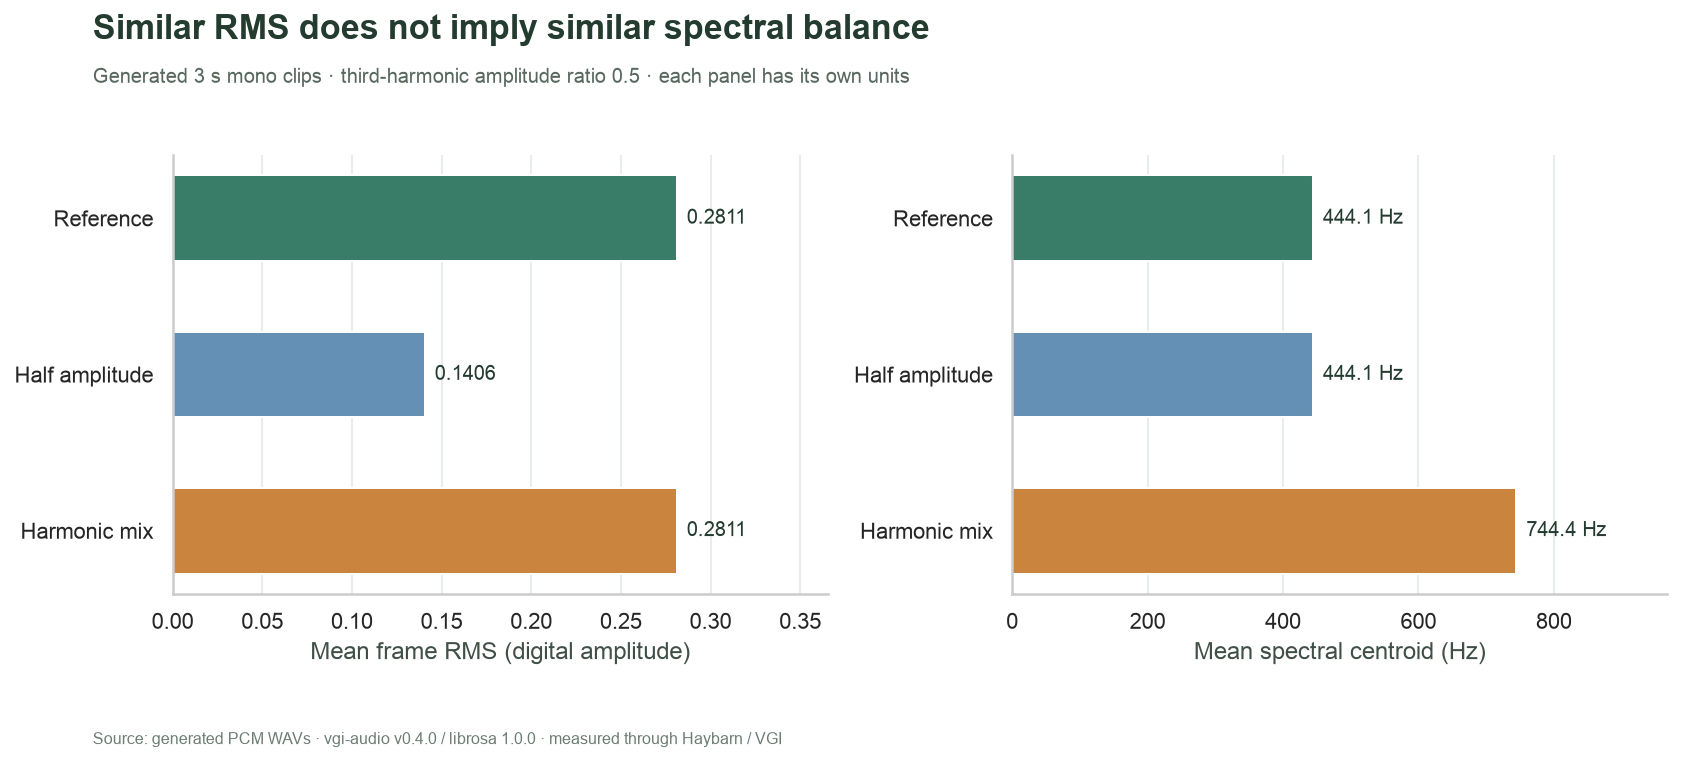

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.3))
colors = [COLORS[label] for label in comparison.label]
for ax, column, xlabel in zip(
    axes, ["rms", "centroid_hz"], ["Mean frame RMS (digital amplitude)", "Mean spectral centroid (Hz)"], strict=True
):
    values = comparison[column].astype(float)
    bars = ax.barh(comparison.label, values, color=colors, height=0.55)
    labels = [f"{v:.4f}" if column == "rms" else f"{v:.1f} Hz" for v in values]
    ax.bar_label(bars, labels=labels, padding=5, fontsize=10)
    ax.set_xlim(0, max(values) * 1.3)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
chart(
    fig,
    "Similar RMS does not imply similar spectral balance",
    f"Generated 3 s mono clips · third-harmonic amplitude ratio {HARMONIC_RATIO:g} · each panel has its own units",
)

## Sweep the harmonic ratio at a fixed designed RMS

Five additional clips span zero through the chosen ratio. SQL computes the
centroid residual and RMS deviation, then orders the measured curve. We expect
the centroid to rise with harmonic weight while level stays nearly constant.
At a ratio of zero all sweep inputs coincide, so a flat curve is the expected result.

In [11]:
%%sql sweep <<
SELECT harmonic_ratio, rms, relative_level_db, centroid_hz, ideal_centroid_hz,
       centroid_hz - ideal_centroid_hz AS centroid_residual_hz
FROM compared WHERE position >= 10 ORDER BY harmonic_ratio, clip_id;

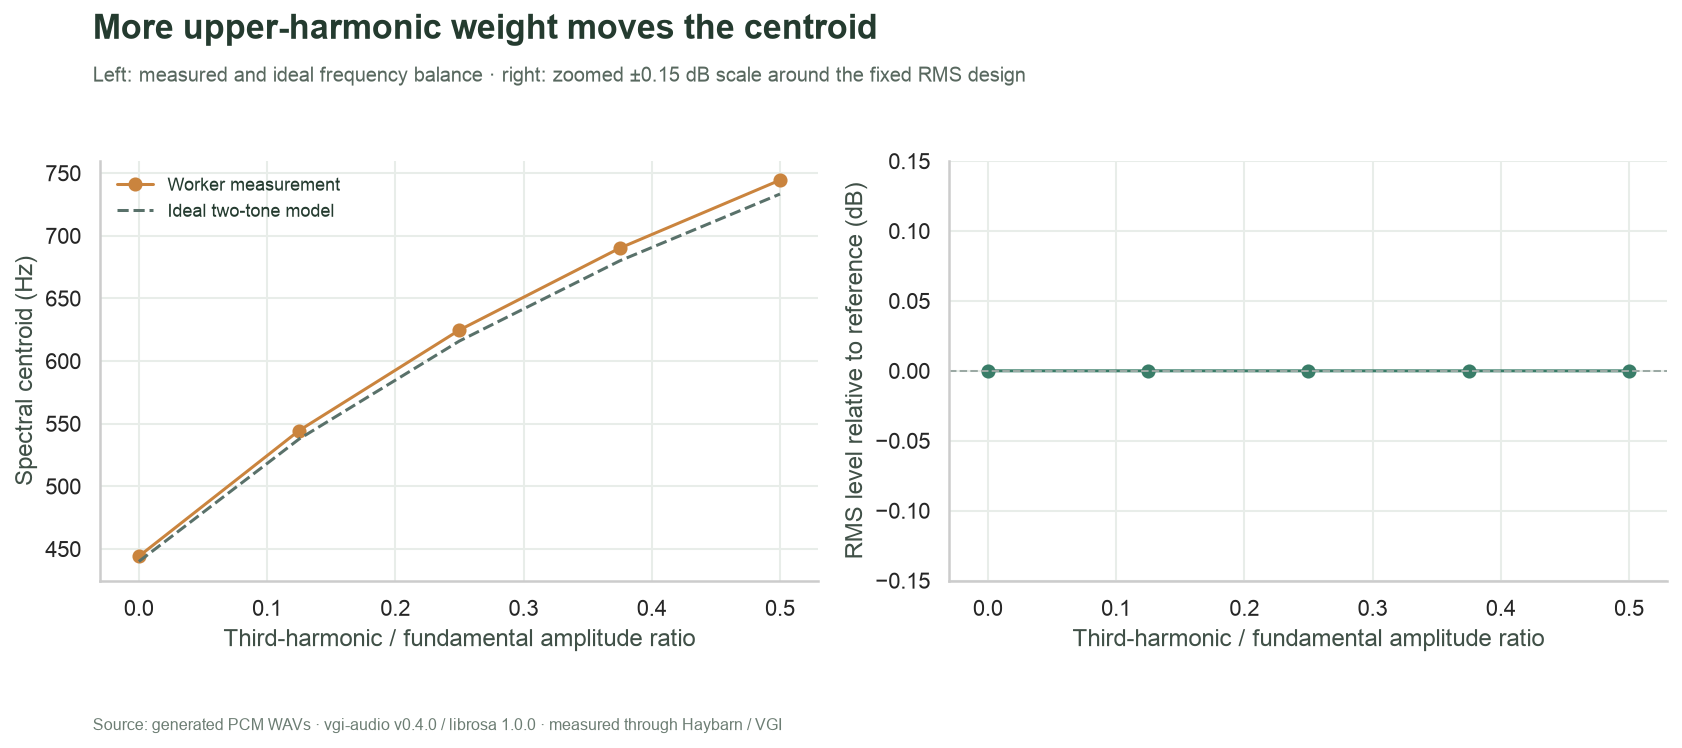

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
axes[0].plot(sweep.harmonic_ratio, sweep.centroid_hz, "o-", color=COLORS["Harmonic mix"], label="Worker measurement")
axes[0].plot(sweep.harmonic_ratio, sweep.ideal_centroid_hz, "--", color="#59716A", label="Ideal two-tone model")
axes[0].set_ylabel("Spectral centroid (Hz)")
axes[0].legend(fontsize=9)
axes[1].plot(sweep.harmonic_ratio, sweep.relative_level_db, "o-", color=COLORS["Reference"])
axes[1].axhline(0, color="#9BA9A4", linestyle="--", linewidth=1)
axes[1].set_ylabel("RMS level relative to reference (dB)")
axes[1].set_ylim(-0.15, 0.15)
for ax in axes:
    ax.set_xlabel("Third-harmonic / fundamental amplitude ratio")
    ax.set_xlim(-0.03, max(0.1, HARMONIC_RATIO) + 0.03)
chart(
    fig,
    "More upper-harmonic weight moves the centroid",
    "Left: measured and ideal frequency balance · right: zoomed ±0.15 dB scale around the fixed RMS design",
)

In [13]:
%%sql sweep_summary <<
SELECT max(abs(centroid_hz - ideal_centroid_hz)) AS max_centroid_residual_hz,
       max(abs(relative_level_db)) AS max_level_deviation_db
FROM compared WHERE position >= 10;

In [14]:
s = sweep_summary.iloc[0]
prose(
    f"Across the selected sweep, the largest centroid-model residual is "
    f"**{s.max_centroid_residual_hz:.2f} Hz** and the largest relative-level deviation is "
    f"**{s.max_level_deviation_db:.4f} dB**. The residual reflects the actual framed "
    "feature extractor rather than a substitute calculation in Python. Neither this centroid "
    "nor RMS alone establishes perceived loudness or listening quality."
)

Across the selected sweep, the largest centroid-model residual is **11.09 Hz** and the largest relative-level deviation is **0.0000 dB**. The residual reflects the actual framed feature extractor rather than a substitute calculation in Python. Neither this centroid nor RMS alone establishes perceived loudness or listening quality.

## Check the controlled relationships

Use exact checks for the WAV format, NULL handling and row grain, and tolerances
for framed measurements: 0.02 dB for halving amplitude, 0.1 dB for constant-level
mixes, 2 Hz for gain-invariant centroid, and 20 Hz for the ideal two-tone model.
These tolerances describe this controlled signal family and pinned implementation.

In [15]:
%%sql checks <<
SELECT 'every designed clip measured' AS check_name,
       count(*) = 8 AND count(rms) = 8 AND count(centroid_hz) = 8 AS passed FROM compared
UNION ALL SELECT 'native format and duration',
       bool_and(duration_s = 3 AND sample_rate_hz = 22050 AND channels = 1) FROM compared
UNION ALL SELECT 'unique clip identity', count(*) = count(DISTINCT clip_id) FROM compared
UNION ALL SELECT 'invalid bytes stay unavailable',
       duration_s IS NULL AND rms IS NULL AND centroid_hz IS NULL FROM measured WHERE clip_id = 'invalid'
UNION ALL SELECT 'half amplitude yields expected dB',
       abs(relative_level_db - 20 * log10(0.5)) < 0.02 FROM compared WHERE clip_id = 'quiet'
UNION ALL SELECT 'amplitude scaling preserves centroid',
       abs(q.centroid_hz - r.centroid_hz) < 2
       FROM compared q CROSS JOIN compared r WHERE q.clip_id = 'quiet' AND r.clip_id = 'reference'
UNION ALL SELECT 'normalized mixes stay near reference level',
       bool_and(abs(relative_level_db) < 0.1) FROM compared WHERE gain = 1
UNION ALL SELECT 'centroid agrees with approximate two-tone model',
       bool_and(abs(centroid_hz - ideal_centroid_hz) < 20) FROM compared;

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), "A signal relationship failed"
prose(
    f"**All {len(checks)} SQL relationships passed.** Malformed bytes did not "
    "become a zero-valued feature or prevent valid clips from being measured."
)

,check_name,passed
0,every designed clip measured,True
1,native format and duration,True
2,unique clip identity,True
3,invalid bytes stay unavailable,True
4,half amplitude yields expected dB,True
5,amplitude scaling preserves centroid,True
6,normalized mixes stay near reference level,True
7,centroid agrees with approximate two-tone model,True


**All 8 SQL relationships passed.** Malformed bytes did not become a zero-valued feature or prevent valid clips from being measured.

## Experiment: equal amplitudes, same designed RMS

Change **`HARMONIC_RATIO = 0.5` to `HARMONIC_RATIO = 1.0`**, restart, and run all.
Predict that the harmonic mix's centroid moves toward **880 Hz**, the equal-weight
midpoint of 440 and 1320 Hz, while its relative RMS level remains near **0 dB**.
Compare both panels of the first figure and the endpoint of the sweep.

The half-amplitude control should retain its approximately −6.02 dB level change.
This experiment tests these synthetic tones; it does not establish how real music
will sound. Reset to **0.5** for the saved default. The [guide](README.md) provides
a command that saves the experiment separately.

In [17]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)